# Morgan Fingerprint 学習用実装
- Morgan Fingerprint の仕組みを理解するために、RDKit のソースコードを参考にしながら Python で学習用実装を作ってみました。
- RDKit を使えば Morgan Fingerprint を簡単に生成できますが、内部でどのような計算が行われているのかを意識する機会はあまりありません。
- この Notebook では、Morgan Fingerprint が生成される過程を追いながらアルゴリズムの動作を確認できます。
    - 原子インバリアント (Atom Invariant) の生成
    - 原子近傍環境 (Atom Neighborhood) の拡張
    - Morgan 識別子 (Morgan Identifier) の計算
    - `BitInfoMap` の構築
- また、計算途中の中間結果を表示できるようにしているため、各段階で何が起きているのかを確認できます。
- なお、本実装は Morgan Fingerprint の内部アルゴリズムを学ぶことを目的とした個人的な学習用実装であり、RDKit の完全な移植や置き換えを目指したものではありません。
- 動作確認は以下の環境で行いました。
    - Python 3.10.18
    - RDKit 2025.03.5
    - pandas 2.3.1
- `MyGetMorganIdentifier()` は、Morgan 識別子 (Morgan Identifier) と原子近傍領域 (Atom Neighborhood) を格納した `DataFrame` を返します。
    - `DataFrame` の行は原子 index に対応します。
    - `radius` 列(整数) は Morgan 識別子を表します。
    - `radius + '_env'` 列は、原子環境 (Atom Environment) に含まれる結合 index の位置を 1 としたビット表現を整数化した値(原子近傍領域)を表します。
    - 原子環境は中心原子 index と radius によって定義されます。
    - RDKit では通常除外される冗長な原子環境についても、対応する Morgan 識別子を出力します。
- `MyGetBitInfoMap()` に上記 `DataFrame` を渡すことで、RDKit と同様に冗長な原子環境を除外した `BitInfoMap` を取得できます。
- `MyGetFingerprint()` に `BitInfoMap` を渡すことで、RDKit と同じ固定長ビット列の Fingerprint を生成できます。
## 注意
- **このノートブックでは前のセルで計算した結果を後続のセルで参照している場合があります。セルは上から順番に実行してください。**
## 参考にした RDKit のソースコード
- Morgan Fingerprint 関連
    - https://github.com/rdkit/rdkit/blob/master/Code/GraphMol/Fingerprints/FingerprintUtil.cpp
    - https://github.com/rdkit/rdkit/blob/master/Code/GraphMol/Fingerprints/MorganGenerator.cpp
- Hash 関連
    - https://github.com/rdkit/rdkit/blob/master/Code/RDGeneral/hash/hash.hpp
## 用語について
- 一部の用語は適切な日本語訳が分からなかったため、本ノートブックでは以下の表記を使用しています。
- 括弧内にはコード中で使用している変数名を示します。
    - Atom Invariant（`AtomInvariant`）: 原子インバリアント
    - Bond Invariant（`BondInvariant`）: 結合インバリアント 
    - Atom Component（`AtomComponent`）: 原子コンポーネント
    - Neighbor Information（`Neighbor`）: 隣接情報
    - Chirality Information（`LooksChiral`）: 原子の立体情報（R/S）
    - Atom Environment (center atom index, radius) : 原子環境
    - Atom Neighborhood（`atomNeighborhood`) : 原子近傍領域

In [1]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem import rdMolDescriptors # for GetConnectivityInvariants
from rdkit.Chem import rdCIPLabeler
from rdkit.DataStructs.cDataStructs import ExplicitBitVect
import pandas as pd
from IPython.display import SVG # to display molecules in jupyter notebook
from collections import defaultdict

## 目次
0. Morgan Fingerprint の基礎
1. radius=0 の Morgan 識別子の計算
2. radius>0 の Morgan 識別子の計算
3. 冗長な局所環境の除外
4. Morgan Fingerprint の固定長への変換
5. 立体情報および同位体情報の例

## 0. Morgan Fingerprint の基礎
- Morgan Fingerprint は、分子中に存在する原子環境（atom environment）から生成されます。
- 原子環境は、中心原子と radius によって定義されます。
    - radius は、中心原子から何結合先までを原子環境に含めるかを表します。
    - 原子環境は通常 `(中心原子 index, radius)` の形式で表現します。
        - 例えば `(2, 1)` は、原子 index 2 を中心とし、そこから 1 結合先までを含む原子環境を表します。
- 各原子環境に対して Morgan 識別子（Morgan Identifier）が計算されます。
    - RDKit では、Morgan 識別子は符号なし 32 ビット整数で表現されます。
    - Morgan 識別子は、その原子環境に含まれる原子および結合の情報から計算されます。
    - 同じ情報を持つ原子環境からは同じ Morgan 識別子が得られます。
    - 異なる原子環境からは通常は異なる Morgan 識別子が得られます。
        - ただし、この性質は数学的に保証されているわけではありません。
        - そのため、異なる原子環境から同じ Morgan 識別子が生成される可能性があります。
- Morgan Fingerprint は、分子中の原子環境から生成された Morgan 識別子を用いて構築されます。
    - 各 Morgan 識別子が分子中に存在するかどうかを表すビットベクトル型の Fingerprint があります。
    - 各 Morgan 識別子が分子中に何回出現したかを表すカウントベクトル型の Fingerprint もあります。
- 以下のセクションでは、RDKitを使用して Morgan Fingerprint を生成し、それに含まれる情報を詳しく見ていきます。

### RDKit での Morgan Fingerprint の例
- 実際に RDKit を用いてプロパノールの Morgan Fingerprint を生成してみます。
    - ここで生成するのは、固定長ビット列へ変換する前の基本となる Fingerprint です。
        - 各 Morgan 識別子の出現回数を取得しています。
        - この Fingerprint の情報から固定長ビット列の Fingerprint が作成されます（4. で説明します）。
    - この Fingerprint は概念的には非常に大きなカウントベクトルですが、実際には非ゼロ要素のみが保持されています。
        - そのため `fp.GetNonzeroElements()` を利用し、実際に分子中に存在する原子環境に対応する Morgan 識別子のみを出力しています。

In [2]:
mol = Chem.MolFromSmiles("CCCO")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=2) # radius=2 の Morgan Fingerprint の Generator
ao = rdFingerprintGenerator.AdditionalOutput() # 追加出力の指定
ao.AllocateBitInfoMap() # 追加出力に BitInfoMap を指定
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao) # Morgan Fingerprint の生成
for key in fp.GetNonzeroElements(): # GetNonzeroElements() で存在する原子環境のみに
    print(f"MorganIdentifier= {key} count= {fp[key]}")

MorganIdentifier= 864662311 count= 1
MorganIdentifier= 1173125914 count= 1
MorganIdentifier= 1365892349 count= 1
MorganIdentifier= 1535166686 count= 1
MorganIdentifier= 2245384272 count= 2
MorganIdentifier= 2246728737 count= 1
MorganIdentifier= 3542456614 count= 1
MorganIdentifier= 4023654873 count= 1


- 8 種類の Morgan 識別子が得られていることがわかります。
    - Morgan 識別子 `2245384272` に対応する原子環境は 2 個存在します。
    - その他の Morgan 識別子に対応する原子環境は、それぞれ 1 個ずつ存在します。
- 続いて、これらの Morgan 識別子がどの原子環境に対応しているのかを確認してみます。
    - RDKit では `ao.GetBitInfoMap()` を使うことで調べられます。

MorganIdentifier= 864662311  ((3, 0),)
MorganIdentifier= 1173125914  ((1, 1),)
MorganIdentifier= 1365892349  ((2, 2),)
MorganIdentifier= 1535166686  ((3, 1),)
MorganIdentifier= 2245384272  ((1, 0), (2, 0))
MorganIdentifier= 2246728737  ((0, 0),)
MorganIdentifier= 3542456614  ((0, 1),)
MorganIdentifier= 4023654873  ((2, 1),)


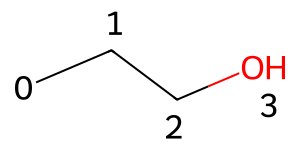

In [3]:
BitInfoMap = ao.GetBitInfoMap()
for key in BitInfoMap:
    print(f"MorganIdentifier= {key}  {BitInfoMap[key]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

- 各 Morgan 識別子に対して、対応する原子環境が `(中心原子 index, radius)` の形式で表示されます。
    - 例えば Morgan 識別子 `864662311` は `(3, 0)` に対応しています。
        - これは原子 index 3 自身だけから構成される原子環境です。
    - Morgan 識別子 `1173125914` は `(1, 1)` に対応しています。
    - Morgan 識別子 `2245384272` は `(1, 0)` と `(2, 0)` の両方に対応しています。
        - この場合は、異なる原子環境から同じ Morgan 識別子が得られています。
- このように、各 Morgan 識別子に対して、それに対応する分子中の原子環境を取得できます。
- Morgan Fingerprint の生成において最も重要な処理は、各原子環境に対して Morgan 識別子を計算することです。
- 以下では、Morgan 識別子がどのように計算されるのかを、Python による実例を示しながら説明します。

## 1. radius=0 の Morgan 識別子の計算
- Morgan 識別子は radius=0, 1, 2, ... の順に計算されます。
    - `radius=0` の Morgan 識別子は、原子自身の情報のみから計算されます。
    - `radius>0` の Morgan 識別子は、直前の radius の Morgan 識別子を利用して計算されます。
        - つまり、`radius=n` の Morgan 識別子は `radius=n-1` の Morgan 識別子から計算されます。
- そこでまず、`radius=0` の Morgan 識別子がどのように計算されるのかを見ていきます。
- 本ノートブックでは、次の手順で計算を追跡します。
    - 各原子について、原子情報を並べた原子コンポーネント（Atom Component）を作成します。
    - 各原子コンポーネントをハッシュ化し、原子インバリアント（Atom Invariant）を計算します。
        - 原子インバリアントは符号なし 32 ビット整数です。
    - 計算された原子インバリアントを `radius=0` の Morgan 識別子として利用します。

### 原子コンポーネント (Atom Component)
- 各原子の Morgan 識別子を計算するために、まず原子コンポーネントを作成します。
- 原子コンポーネントは、Morgan 識別子の計算に使用する原子情報を並べた整数列（本ノートブックでは Python のリスト）です。
    1. 原子番号
    2. 原子の総次数（水素を含む隣接原子数）
    3. 結合している水素数
    4. 形式電荷
    5. 標準原子量との差分
        - 標準原子量との差分は、質量差を `int()` により整数化した値です。
    6. 環所属フラグ
        - 環原子の場合のみ末尾に要素 `1` を追加します。
        - そのため、環原子では長さ 6、非環原子では長さ 5 のリストになります。
- 原子コンポーネントは次の形式になります。
    - `[原子番号, 隣接原子数, 結合水素数, 形式電荷, 同位体差 (, 環所属フラグ)]`
- `MyGetAtomComponents()` は、分子中の各原子の原子コンポーネントを返す関数です。

In [4]:
def MyGetAtomComponents(mol, verbose=0):
    # 全原子の原子コンポーネント AtomComponents のリストを作成する
    ptable = Chem.GetPeriodicTable()
    AtomComponents = []
    for atom in mol.GetAtoms():
        atomic_num = atom.GetAtomicNum()
        total_degree = atom.GetTotalDegree()
        total_num_hs = atom.GetTotalNumHs(True)
        formal_charge = atom.GetFormalCharge()
        delta_mass = int( atom.GetMass() - ptable.GetAtomicWeight(atomic_num) )
        components = [ atomic_num, total_degree, total_num_hs, formal_charge, delta_mass ]
        if atom.IsInRing():
            components.append(1)
        if verbose:
            print(f"atom= {atom.GetIdx()}  AtomComponent= {components}")
        AtomComponents.append(components)
    return AtomComponents

- プロパノールについて原子コンポーネントを計算してみます。

In [5]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol, verbose=1)

atom= 0  AtomComponent= [6, 4, 3, 0, 0]
atom= 1  AtomComponent= [6, 4, 2, 0, 0]
atom= 2  AtomComponent= [6, 4, 2, 0, 0]
atom= 3  AtomComponent= [8, 2, 1, 0, 0]


### 原子コンポーネントから原子インバリアントの計算 (= radius=0 の Morgan 識別子)
#### ハッシュ計算
- 原子インバリアントは符号なし 32 ビット整数です。
- 原子コンポーネントに含まれる複数の情報を 1 つの整数へ変換するために、ハッシュ計算が使用されます。
- RDKit では、Boost の `hash_combine()` と同じ考え方のハッシュ計算が使用されています。
- 学習用に Python 版を実装しました。
    - `hash_combine()` は中核となる関数で、既存のハッシュ値 (`seed`) に新しい値 (`value`) を追加した結果を返します。
        - ビットシフト、加算、および XOR を用いて値を混合します。
        - 黄金比（Golden Ratio）の小数部分に由来するマジックナンバー `0x9e3779b9` を利用し、入力値の変化がハッシュ値全体へ反映されやすくなるようにしています。
    - `vector_hash()` は複数の数値から累積ハッシュ値を計算する関数です。
    - `pair_hash()` は 2 つの数値からハッシュ値を計算する関数です（後で利用します）。

In [6]:
def hash_combine(seed, value): # Boost ライブラリの hash_combine 関数
    MASK32 = 0xffffffff # python の int は任意精度整数なので、uint32_tを再現するために MASK32 と & 演算
    seed ^= ( value + 0x9e3779b9 + ( (seed << 6) & MASK32) + (seed >> 2) )
    return seed & MASK32 # 32bitの範囲する必要がある

def vector_hash(values, verbose=0): # 複数変数の累積ハッシュ値を計算する
    seed = 0
    if verbose:
        print(f'seed={seed}')
    for value in values:
        org_seed = seed
        seed = hash_combine( seed, value )
        if verbose:
            print(f'combine seed {org_seed}, value {value} -> seed {seed}')
    return seed

def pair_hash(a, b): # 2変数のハッシュ値を計算する
    seed = 0
    seed = hash_combine(seed, a)
    seed = hash_combine(seed, b)
    return seed

- 原子コンポーネントから原子インバリアントを計算するには `vector_hash()` を利用します。
    - 数値列を `vector_hash()` に渡すと、ハッシュ値として符号なし 32 ビット整数が返されます。
- 例として、プロパノールの原子 0 の原子コンポーネント `[6, 4, 3, 0, 0]` がどのようにハッシュ化されるかを見てみます。

In [7]:
print(f"hash value = {vector_hash([6, 4, 3, 0, 0], verbose=1)}")

seed=0
combine seed 0, value 6 -> seed 2654435775
combine seed 2654435775, value 4 -> seed 3449077331
combine seed 3449077331, value 3 -> seed 4216881219
combine seed 4216881219, value 0 -> seed 1215638218
combine seed 1215638218, value 0 -> seed 2246728737
hash value = 2246728737


- 最終的に得られた原子インバリアント `2246728737` が、プロパノールの原子 0 に対応する `radius=0` の Morgan 識別子になります。
- `MyGetAtomInvariants()` は、各原子コンポーネントから全原子の原子インバリアントを計算する関数です。

In [8]:
def MyGetAtomInvariants(AtomComponents):
    # 原子コンポーネントのリストから原子インバリアントのリストを作成する
    AtomInvariants=[]
    for components in AtomComponents:
        AtomInvariants.append(vector_hash(components))
    return AtomInvariants

- RDKit には、`radius=0` の原子インバリアントを返す `rdMolDescriptors.GetConnectivityInvariants()` が用意されています。
- RDKit が計算した原子インバリアントと、`MyGetAtomInvariants()` が計算した原子インバリアントを比較してみます。

In [9]:
mol = Chem.MolFromSmiles("CCCO")
rdkit_invars = rdMolDescriptors.GetConnectivityInvariants(mol) # RDKit における原子インバリアントの取得関数
print('GetConnectivityInvariants(mol)',rdkit_invars)
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
for atom in mol.GetAtoms():
    a_idx = atom.GetIdx()
    print(
        f"atom={a_idx} ",
        f"components={AtomComponents[a_idx]} ",
        f"atomInvariant={AtomInvariants[a_idx]} ",
        f"rdkit={rdkit_invars[a_idx]}"
    )

GetConnectivityInvariants(mol) [2246728737, 2245384272, 2245384272, 864662311]
atom=0  components=[6, 4, 3, 0, 0]  atomInvariant=2246728737  rdkit=2246728737
atom=1  components=[6, 4, 2, 0, 0]  atomInvariant=2245384272  rdkit=2245384272
atom=2  components=[6, 4, 2, 0, 0]  atomInvariant=2245384272  rdkit=2245384272
atom=3  components=[8, 2, 1, 0, 0]  atomInvariant=864662311  rdkit=864662311


- 全ての原子で RDKit と同じ値が得られていることがわかります。
- この結果から、本ノートブックの実装でも原子インバリアントを同様の方法で計算できていることが確認できます。
- そして、計算された原子インバリアントが `radius=0` の Morgan 識別子となります。
- 得られた Morgan 識別子と対応する原子環境を整理することで、`radius=0` に対応する `BitInfoMap` を構築できます。

## 2. radius>0 の Morgan 識別子の計算
- `radius>0` の Morgan 識別子は、直前の radius で計算された原子インバリアントを利用して計算されます。
- `radius=n` の原子環境に対応する Morgan 識別子は、概ね以下の流れで計算されます。
    - 隣接情報（Neighbor Information）を `radius=n-1` の原子インバリアントから構築します。
        - 隣接情報は、各隣接原子についての `(結合インバリアント, 原子インバリアント)` のリストです。
        - 結合インバリアントは、原子どうしを結ぶ結合の種類や立体情報を表す整数値です。
    - 原子の立体情報（Chirality Information）を構築します。
        - 原子の立体不斉の情報 (R/S) を表す整数値です。
    - 以下の情報を順に追加しながらハッシュ計算を行い、新たな原子インバリアントを計算します。
        1. 初期値として `radius-1` の値を設定します。
        2. 中心原子の原子インバリアントを追加してハッシュ化します。
        3. 隣接情報を追加してハッシュ化します。
        4. 必要に応じて原子の立体情報を追加してハッシュ化します。
- このようにして得られた新たな原子インバリアントが、`radius=n` の Morgan 識別子となります。

### 結合インバリアント (Bond Invariant)
- `radius>0` の Morgan 識別子を計算する際には、原子どうしがどのような結合で接続されているかを表す情報が必要となります。
    - そのため、各結合に対して結合インバリアントを計算して利用します。
- 結合インバリアントは以下のように計算されます。
    - 初期値として `1` が設定されます。
        - これは「結合あり」を表す最も単純な値であり、結合タイプや結合の立体情報を使用しない場合の値です。
            - 結合の立体情報とは、二重結合の幾何異性体(E/Z)の情報(Double-Bond Stereochemistry Information)です 。
        - 本ノートブックでは、このケースは扱いません。
    - 立体情報を使用しない場合、または結合が二重結合でない場合、あるいは結合の立体情報が存在しない場合は `int(bond.GetBondType())` が使用されます。
        - 単結合は `1`
        - 二重結合は `2`
        - 三重結合は `3`
        - 芳香族結合は `12`
        - その他の結合型についても RDKit が定義する整数値が利用されます。
    - 上記以外の場合は、結合タイプと結合の立体情報を組み合わせた値が使用されます。
        - `100 + 10 * int(bond.GetBondType()) + int(bond.GetStereo())`
        - `bond.GetStereo()` は結合の立体情報を表します。
            - `0` : STEREONONE
            - `1` : STEREOANY
            - `2` : STEREOZ
            - `3` : STEREOE
- `BondType` および `Stereo` の詳細は、RDKit の Bond クラスで定義されています。
    - https://www.rdkit.org/docs/cppapi/classRDKit_1_1Bond.html
- `MyGetBondInvariants()` は、分子中の全結合について結合インバリアントを計算する関数です。

In [10]:
def MyGetBondInvariants(mol, useBondTypes=True, useChiral=False, verbose=0):
    # 全結合の結合インバリアントのリストを作成する
    stereoOffset = 100
    bondTypeOffset = 10
    BondInvariants = []
    for bond in mol.GetBonds():
        invariant = 1 # 初期値
        if useBondTypes:
            if ( not useChiral or bond.GetBondType() != Chem.BondType.DOUBLE or bond.GetStereo() == Chem.BondStereo.STEREONONE ):
                invariant = int(bond.GetBondType()) # 立体情報を利用しない or 2重結合でない or stereo情報が無い場合
            else:
                invariant = ( stereoOffset + bondTypeOffset * int(bond.GetBondType()) + int(bond.GetStereo()) )
        if verbose:
            print(f'bond={bond.GetIdx()} bondInvariants={invariant}  ' + \
                  f'bond.GetBondType={int(bond.GetBondType())}  bond.GetStereo={int(bond.GetStereo())}')
        BondInvariants.append(invariant)
    return BondInvariants

- プロパノールについて結合インバリアントを計算してみます。

In [11]:
mol = Chem.MolFromSmiles("CCCO")
BondInvariants = MyGetBondInvariants(mol,verbose=1)

bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0


- 全て単結合であり立体情報も存在しないため、全結合の結合インバリアントは `1` となります。
- 次に trans-2-butene について結合インバリアントを計算してみます。
    - `useChiral=False` の場合は結合の立体情報が考慮されません。
    - RDKit の Morgan Fingerprint でも、デフォルトでは結合の立体情報は使用されません。

useChiral=False (default)
bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=2  bond.GetBondType=2  bond.GetStereo=3
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
useChiral=True
bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=123  bond.GetBondType=2  bond.GetStereo=3
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0


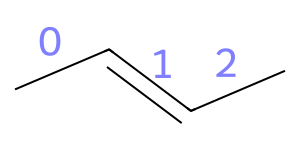

In [12]:
mol = Chem.MolFromSmiles("C\C=C\C")
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol, verbose=1)
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True, verbose=1)
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addBondIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

- 二重結合である bond 1 は E/Z 立体情報を持っています。
- `useChiral=False` の場合は結合タイプのみが利用されるため、結合インバリアントは `2` となります。
- `useChiral=True` の場合は結合の立体情報も利用されるため、`100 + 10 × 2 + 3 = 123` となり、結合インバリアントは `123` となります。

### 隣接情報 (Neighbor Information)
- `MyGetNeighbors()` は、分子中の全原子について隣接情報（Neighbor Information）を構築する関数です。
- 隣接情報は、各原子に隣接する原子およびそれらを結ぶ結合の情報をまとめたリストです。
    - 各要素は `(結合インバリアント, 原子インバリアント)` の形式で表されます。
    - 結合インバリアントは、中心原子と隣接原子を結ぶ結合の情報を表します。
    - 原子インバリアントは、隣接原子に対する `radius=n−1` の原子インバリアントです。
- 各原子の隣接情報は、`(結合インバリアント, 原子インバリアント)` のタプルについて辞書順でソートされます。
    - まず結合インバリアントで比較し、同じ場合は原子インバリアントで比較します。
    - 後続のハッシュ計算では、情報を追加する順序も結果に影響します。
    - そのため、原子番号の並び方に依存しない一定の結果を得るためにソートを行います。
    - また、後で立体情報を判定する際にも、このソート済みの隣接情報を利用します。
- `MyGetNeighbors()` は、このような隣接情報を全原子について構築して返します。

In [13]:
def MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=0):
    # 全原子の隣接情報(結合インバリアント, 原子インバリアント) のリストを作成する
    Neighbors = []
    for atom in mol.GetAtoms():
        neigh = []
        for bond in atom.GetBonds(): # 原子の全結合でループ
            other = bond.GetOtherAtom(atom) # 結合先原子を取得
            neigh.append( (BondInvariants[bond.GetIdx()] , AtomInvariants[other.GetIdx()] ) )
        neigh.sort() # 得られた隣接情報をソートする
        if verbose:
            print(f"atom= {atom.GetIdx()}  neighbor= {neigh}")
        Neighbors.append(neigh)
    return Neighbors

- プロパノールについて隣接情報を計算してみます。
    - 原子 0 は原子 1 と単結合しているため、`[(1, 2245384272)]` となります。
    - 原子 1 は原子 0 および原子 2 と単結合しているため、`[(1, 2245384272), (1, 2246728737)]` となります。

In [14]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)

atom= 0  neighbor= [(1, 2245384272)]
atom= 1  neighbor= [(1, 2245384272), (1, 2246728737)]
atom= 2  neighbor= [(1, 864662311), (1, 2245384272)]
atom= 3  neighbor= [(1, 2245384272)]


- 各タプルの第一要素は結合インバリアント、第二要素は隣接原子の `radius=n−1` における原子インバリアントを表しています。
- 次に trans-2-butene について隣接情報を計算してみます。
    - `useChiral=True` を指定しない場合、結合の立体情報は結合インバリアントに反映されません。

In [15]:
mol = Chem.MolFromSmiles("C\C=C\C")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)

useChiral=False (default)
atom= 0  neighbor= [(1, 2246703798)]
atom= 1  neighbor= [(1, 2246728737), (2, 2246703798)]
atom= 2  neighbor= [(1, 2246728737), (2, 2246703798)]
atom= 3  neighbor= [(1, 2246703798)]
useChiral=True
atom= 0  neighbor= [(1, 2246703798)]
atom= 1  neighbor= [(1, 2246728737), (123, 2246703798)]
atom= 2  neighbor= [(1, 2246728737), (123, 2246703798)]
atom= 3  neighbor= [(1, 2246703798)]


- `useChiral=False` の場合、二重結合は結合インバリアント `2` として扱われます。
- `useChiral=True` の場合、E/Z 立体情報が結合インバリアントに反映されるため、値が `123` に変化します。
- その結果、隣接情報も変化します。
- この違いは後続のハッシュ計算結果に反映され、最終的な Morgan 識別子にも影響します。
- 結合の立体情報の実例については、セクション 5 で説明します。

### 原子の立体情報 (Chirality Information)
- `MyGetLooksChirals()` は、分子中の全原子について原子の立体情報（Chirality Information）を計算する関数です。
- 立体情報を計算する前に、`rdCIPLabeler.AssignCIPLabels(mol)` を実行し、各原子に CIP の立体情報を設定しておく必要があります。
- 各原子の立体情報は次のように決定されます。
    - 原子の立体情報を使用しない場合は `0`
        - Morgan Fingerprint はデフォルトでは原子の立体情報を使用しません。
    - CIP の立体情報が存在しない場合は `0`
    - 不斉中心候補ではない場合は `0`
    - 上記のいずれにも該当しない場合は `atom.GetProp("_CIPCode")` の値に応じて
        - `"R"` → `3`
        - `"S"` → `2`
        - その他 → `1`
          が設定されます。
- このようにして得られた整数値が、後で Morgan 識別子を計算する際に利用されます。
#### 不斉中心候補の判定
- 原子が不斉中心候補であるかどうかは `morgan_looks_chiral_atom()` により判定します。
- 判定手順は以下の通りです。
    - 対象原子に立体情報の指定が存在しない場合は `False`
    - 単結合以外の結合が存在する場合は `False`
    - 隣接原子の原子インバリアントに同じ値が複数存在する場合は `False`
        - ソート済みの隣接情報を順番に確認します。
        - 直前の原子インバリアントと同じ値が現れた場合、その原子は不斉中心候補ではありません。
    - 上記の条件に該当しない場合は `True`
- ここで隣接情報がソートされていることで、同じ原子インバリアントが存在するかどうかを効率的に判定できます。

In [16]:
def morgan_looks_chiral_atom(atom, Neighbor):
    # 原子が Chiral か否かを判定する (Neighbor の AtomInvariant から判断)
    if atom.GetChiralTag() == Chem.rdchem.ChiralType.CHI_UNSPECIFIED:
        return False # 対象原子に立体情報の記載がなかった
    prev_inv = None
    for bond_inv, atom_inv in Neighbor: # Neighbor は sort されている前提
        if bond_inv != 1: # 単結合でなかったら Chiral でない
            return False
        if prev_inv is not None and atom_inv == prev_inv: # 直前と同じ AtomInvariant であれば Chiral でない
            return False
        prev_inv = atom_inv
    return True

def MyGetLooksChirals(mol, Neighbors, useChiral=False):
    # 原子の立体を調べて立体情報 LooksChiral のリストを作成する
    LooksChirals = []
    for atom, neigh in zip(mol.GetAtoms(), Neighbors):
        if not useChiral: # 立体情報を使わない時
            LooksChirals.append(0) # 0を追加
            continue
        if not morgan_looks_chiral_atom(atom, neigh): # 立体情報の記載なし or 同じ Neighbors が存在(不斉原子でない)
            LooksChirals.append(0) # 0を追加
            continue
        cip = atom.GetProp("_CIPCode") if atom.HasProp("_CIPCode") else "" # 事前に rdCIPLabeler.AssignCIPLabels(mol) されている
        if cip == "R":
            LooksChirals.append(3) # Rなら3を追加
        elif cip == "S":
            LooksChirals.append(2) # Sなら2を追加
        else:
            LooksChirals.append(1) # 上記以外なら1を追加
    return LooksChirals

#### プロパノールの例
- プロパノールについて立体情報を計算してみます。
- デフォルトでは原子の立体情報を使用しないため、全ての原子で `0` となります

In [17]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors))

[0, 0, 0, 0]


#### 不斉中心を持つ分子の例
- 不斉中心を持つ分子として `CC[C@@](F)(Cl)Br` を使用します。
- `useChiral=False` の場合は原子の立体情報を使用しないため、全ての原子で `0` となります。
- `useChiral=True` の場合は不斉中心の情報が利用されます。
    - この分子では原子 2 が R 配置であるため、値 `3` が設定されます。

In [18]:
mol = Chem.MolFromSmiles("CC[C@@](F)(Cl)Br")
rdCIPLabeler.AssignCIPLabels(mol)
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors))
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors, useChiral=True))

useChiral=False (default)
[0, 0, 0, 0, 0, 0]
useChiral=True
[0, 0, 3, 0, 0, 0]


- 以降、原子の立体情報を考慮する場合は、この値が Morgan 識別子の計算時に追加されます。
- 原子の立体情報の実例については、セクション 5 で説明します。

### radius=1 の Morgan 識別子の計算
- 以上で、`radius=1` の Morgan 識別子を計算するために必要な情報が揃いました。
- 各原子について、計算に必要な情報は次の通りです。
    - `layer`
        - 現在計算している radius を区別するために使用される値です。
        - `radius-1` の値が利用されます。
        - `radius=1` の計算では `0` となります。
    - `CenterInvariant`
        - 中心原子の原子インバリアントです。
    - `Neighbor`
        - 中心原子の隣接情報です。
    - `LooksChiral`
        - 中心原子の立体情報です。
- `MyRadiusHash()` は、これらの情報をハッシュ化し、新たな原子インバリアントを計算する関数です。
- 計算手順は次の通りです。
    1. 初期値として `layer` を設定します。
    2. 中心原子の原子インバリアントを追加してハッシュ化します。
    3. 隣接情報を追加してハッシュ化します。
        - 隣接情報はあらかじめソートされています。
        - その順番でハッシュ計算へ追加されます。
        - 各隣接原子について `(結合インバリアント, 原子インバリアント)` を `pair_hash()` により 1 つの整数へ変換します。
        - 得られた整数を追加してハッシュ化します。
    4. 中心原子の立体情報が `0` 以外の場合は、それを追加してハッシュ化します。
- 最終的に得られた整数が新たな原子インバリアントとなります。
- この原子インバリアントが `radius=1` の Morgan 識別子として利用されます。
- `MyGetLayerMorganIdentifier()` は、全原子の情報を受け取り、新たな原子インバリアントのリストを返す関数です。

In [19]:
def MyRadiusHash(layer, CenterInvariant, Neighbor, LooksChiral, verbose=0):
    # layer, 中心原子の原子インバリアント、隣接情報、立体情報から、Morgan 識別子を計算する
    seed = layer # 初期 seed 値を設定
    if verbose:
        print(f'seed={seed}')
        org_seed = seed
    seed = hash_combine( seed, CenterInvariant ) # 中心原子の原子インバリアントを付加
    if verbose:
        print(f'combine seed {org_seed}, value {CenterInvariant} -> seed {seed}')
        org_seed = seed
    i=0
    for bond_inv, neigh_inv in Neighbor: # 隣接原子の情報を付加
        ph = pair_hash( bond_inv, neigh_inv ) # 隣接原子への結合インバリアントと隣接原子の原子インバリアントをハッシュ化
        if verbose:
            print(f'hash Neighbor {i} ({bond_inv}, {neigh_inv}) -> {ph}')
        seed = hash_combine( seed, ph ) # ハッシュ化された隣接情報を付加
        if verbose:
            print(f'combine seed {org_seed}, value {ph} -> seed {seed}')
            org_seed = seed
        i += 1
    if LooksChiral != 0: # 立体情報を付加
        seed = hash_combine( seed, LooksChiral )
        if verbose:
            print(f'combine seed {org_seed}, value {ph} -> seed {seed}')
            org_seed = seed
    return seed

def MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals):
    # この layer における分子中の全ての Morgan 識別子のリストを作成する
    MorganIdentifiers=[]
    for i, CenterInvariant in enumerate(AtomInvariants): # 全原子の原子インバリアントでループ
        MorganIdentifiers.append(MyRadiusHash(layer, CenterInvariant, Neighbors[i], LooksChirals[i]))
    return MorganIdentifiers

#### プロパノールの原子 1 の計算例
- プロパノールの原子 1 について、`radius=1` の原子インバリアントを計算してみます。
- `MyRadiusHash()` に必要な情報を渡すと、新たな原子インバリアント `1173125914` が得られます。

In [20]:
layer = 0
CenterInvariant = 2245384272
Neighbor = [(1, 2245384272), (1, 2246728737)]
LooksChiral = 0
MyRadiusHash(layer, CenterInvariant, Neighbor, LooksChiral, verbose=1)

seed=0
combine seed 0, value 2245384272 -> seed 604852745
hash Neighbor 0 (1, 2245384272) -> 1196353357
combine seed 604852745, value 1196353357 -> seed 3587401153
hash Neighbor 1 (1, 2246728737) -> 1203329906
combine seed 3587401153, value 1203329906 -> seed 1173125914


1173125914

- この原子インバリアントが、原子 1 に対応する `radius=1` の Morgan 識別子となります。
#### RDKit との比較
- プロパノールについて `radius=0` および `radius=1` の原子インバリアント（Morgan 識別子）を計算してみます。
- 実際に RDKit が生成した `BitInfoMap` と比較すると、Morgan 識別子が一致していることが分かります。

In [21]:
mol = Chem.MolFromSmiles("CCCO")
AtomInvariants = MyGetAtomInvariants(MyGetAtomComponents(mol))
print("Atom Invariants calculated by this Python implementation")
print(f"radius=0  MorganIdentifiers={AtomInvariants}")
BondInvariants = MyGetBondInvariants(mol)

layer=0
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
print(f"radius=1  MorganIdentifiers={MorganIdentifiers}")

print("Morgan Fingerprint generated by RDKit")
fpgen_r1 = rdFingerprintGenerator.GetMorganGenerator(radius=1) # radius=1 の Morgan Fingerprint の Generator
fp = fpgen_r1.GetSparseCountFingerprint(mol, additionalOutput=ao) # Morgan Fingerprint の生成
BitInfoMap = ao.GetBitInfoMap()
for rd in BitInfoMap:
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}")

Atom Invariants calculated by this Python implementation
radius=0  MorganIdentifiers=[2246728737, 2245384272, 2245384272, 864662311]
radius=1  MorganIdentifiers=[3542456614, 1173125914, 4023654873, 1535166686]
Morgan Fingerprint generated by RDKit
MorganIdentifier=864662311  ((3, 0),)
MorganIdentifier=1173125914  ((1, 1),)
MorganIdentifier=1535166686  ((3, 1),)
MorganIdentifier=2245384272  ((1, 0), (2, 0))
MorganIdentifier=2246728737  ((0, 0),)
MorganIdentifier=3542456614  ((0, 1),)
MorganIdentifier=4023654873  ((2, 1),)


- Python 実装で計算した `radius=0` および `radius=1` の Morgan 識別子が、RDKit の結果と一致していることが確認できます。
#### radius=2 の計算
- 同じ手順により `radius=2` の Morgan 識別子も計算できます。
- 下記の例では、`radius=1` で得られた Morgan 識別子を新たな原子インバリアントとして利用し、`layer=1` として計算しています。

In [22]:
mol = Chem.MolFromSmiles("CCCO")
# radius = 0
AtomInvariants = MyGetAtomInvariants(MyGetAtomComponents(mol))
BondInvariants = MyGetBondInvariants(mol)
# radius = 1
layer=0
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
# radius = 2
AtomInvariants = MorganIdentifiers # radius=1 の MorganIdentifiers を AtomInvariants に代入して同じことを実行
layer=1
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
print("radius=2 Morgan Identifiers calculated by this Python implementation")
print(f"radius=2 MorganIdentifiers={MorganIdentifiers}")

print("Morgan Fingerprint generated by RDKit")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=2) # radius=2 の Morgan Fingerprint の Generator
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao) # Morgan Fingerprint の生成
BitInfoMap = ao.GetBitInfoMap()
for rd in BitInfoMap:
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}")

radius=2 Morgan Identifiers calculated by this Python implementation
radius=2 MorganIdentifiers=[1747430757, 2648393034, 1365892349, 3729693694]
Morgan Fingerprint generated by RDKit
MorganIdentifier=864662311  ((3, 0),)
MorganIdentifier=1173125914  ((1, 1),)
MorganIdentifier=1365892349  ((2, 2),)
MorganIdentifier=1535166686  ((3, 1),)
MorganIdentifier=2245384272  ((1, 0), (2, 0))
MorganIdentifier=2246728737  ((0, 0),)
MorganIdentifier=3542456614  ((0, 1),)
MorganIdentifier=4023654873  ((2, 1),)


- 計算された `radius=2` の Morgan 識別子を確認すると、原子 2 の Morgan 識別子 `1365892349` は RDKit の `(2, 2)` と一致しています。
- 一方で、原子 0、1、3 に対して計算された `radius=2` の Morgan 識別子は RDKit の出力には現れません。
- これは Morgan Fingerprint では冗長な原子環境が除外されるためです。
- 原子環境 `(0, 2)`、`(1, 2)`、`(2, 2)`、`(3, 2)` を確認すると、
    - `(0, 2)` は `radius=1` の `(1, 1)` と同じ原子環境を表すため、後から生成された `(0, 2)` は除外されます。
    - `(3, 2)` は `radius=1` の `(2, 1)` と同じ原子環境を表すため、後から生成された `(3, 2)` は除外されます。
    - `(1, 2)` と `(2, 2)` はどちらも同じ結合集合を含む原子環境となります。このうち一方のみが残されます。
- この結果、4 つの原子環境のうち 1 つだけが採用され、残りは除外されます。
- 次に、どのようにして同一の原子環境を判定しているのか、またなぜ `(2, 2)` が選択されるのかを見ていきます。

## 3. 冗長な原子環境の除外
- Morgan Fingerprint では、同一の原子環境を表す冗長な原子環境が除外されます。
- 原子環境が同一であるかどうかは、その原子環境に含まれる結合の集合によって判定されます。
- 本ノートブックでは、この結合集合を原子近傍領域（atomNeighborhood）として表現します。
- 原子環境は `(中心原子 index, radius)` で表されます。
- 原子近傍領域は、その原子環境に含まれる結合 index の集合をビットベクトルとして表現し、それを整数化したものです。
    - 例えば、結合 index 1、2、3 を含む場合は `14` となります。
    - `14` の二進表現は `0b1110` であり、ビット位置 1、2、3 が `1`、ビット位置 0 が `0` であることを表しています。
- 各 radius で生成された原子環境は `allNeighborhoodsThisRound` に格納されます。
    - 同じ radius で生成された原子環境どうしの比較に利用されます。
    - 各要素は `(原子近傍領域, Morgan 識別子, 中心原子 index)` の形式です。
- `allNeighborhoodsThisRound` はソートされた後、既に出現した原子近傍領域かどうかが判定されます。
- 原子近傍領域が既出である場合、その原子環境は冗長な原子環境として除外されます。

### 原子近傍領域 atomNeighborhood の作成
- `MyGetInitatomNeighborhoods()` は、各原子に隣接する結合を調べ、`radius=1`（`layer=0`）に対応する原子近傍領域を作成します。
- `MyGetatomNeighborhoods()` は、`radius=n` の原子近傍領域から `radius=n+1` の原子近傍領域を作成します。
- `radius=n+1` の原子近傍領域は、自身および隣接原子の `radius=n` における原子近傍領域をビット OR 演算によって結合して作成されます。

In [23]:
def MyGetInitatomNeighborhoods(mol): 
    # 各原子の結合を調べて初期の原子近傍領域のリストを作成
    atomNeighborhoods = []
    for atom in mol.GetAtoms():
        env=0
        for b_idx in [bond.GetIdx() for bond in atom.GetBonds()]:
            env |= (1 << b_idx) # 各原子が持つ結合の、結合indexのbitを1とした整数
        atomNeighborhoods.append(env)
    return atomNeighborhoods

def MyGetatomNeighborhoods(mol, atomNeighborhoods):
    # 原子近傍環境から、全原子の新しい原子近傍領域のリストを作成
    environment_bitsets = [] # 新しく作成される原子近傍領域のリストを格納
    for atom in mol.GetAtoms():
        env = atomNeighborhoods[atom.GetIdx()] # 自分自身の原子近傍領域をセット
        for neig_atom in atom.GetNeighbors():
            env |= atomNeighborhoods[neig_atom.GetIdx()] # 隣接原子の原子近傍領域と OR 演算
        environment_bitsets.append(env)
    return environment_bitsets

- プロパノールについて `radius=1` および `radius=2` の原子近傍領域を計算してみます。
    - 原子 0 の `radius=1` の原子環境には結合 0 が含まれるため、原子近傍領域は `1 (=0b1)` となります。
    - 原子 0 の `radius=2` の原子環境には結合 0 および 1 が含まれるため、原子近傍領域は `3 (=0b11)` となります。
    - 原子 1 の `radius=1` の原子環境には結合 0 および 1 が含まれるため、原子近傍領域は `3 (=0b11)` となります。
    - 原子 1 の `radius=2` の原子環境には結合 0、1、および 2 が含まれるため、原子近傍領域は `7 (=0b111)` となります。

radius =1
atom= 0  atomNeighborhood= 1 = 0b1
atom= 1  atomNeighborhood= 3 = 0b11
atom= 2  atomNeighborhood= 6 = 0b110
atom= 3  atomNeighborhood= 4 = 0b100
radius =2
atom= 0  atomNeighborhood= 3 = 0b11
atom= 1  atomNeighborhood= 7 = 0b111
atom= 2  atomNeighborhood= 7 = 0b111
atom= 3  atomNeighborhood= 6 = 0b110


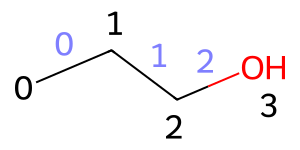

In [24]:
mol = Chem.MolFromSmiles("CCCO")
print("radius =1")
atomNeighborhoods = MyGetInitatomNeighborhoods(mol)
for i, env in enumerate(atomNeighborhoods):
    print(f"atom= {i}  atomNeighborhood= {env} = {bin(env)}")
print("radius =2")
atomNeighborhoods = MyGetatomNeighborhoods(mol, atomNeighborhoods)
for i, env in enumerate(atomNeighborhoods):
    print(f"atom= {i}  atomNeighborhood= {env} = {bin(env)}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addBondIndices = True
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Morgan 識別子および原子近傍領域の計算
- `MyGetMorganIdentifier()` は、これまで説明した処理をまとめて実行する関数です。
- 各 radius における Morgan 識別子と対応する原子近傍領域を計算します。
- `verbose` に `0` 以外の値（デフォルトは `0`）を指定すると、計算過程を表示します。
- 立体情報を考慮しない場合は `MyGetMorganIdentifier(mol, radius=2)` のように指定します。
- 立体情報を考慮する場合は `MyGetMorganIdentifier(mol, radius=2, includeChirality=True)` を使用します。
    - `includeChirality=True` を指定すると、立体情報を含めて Morgan 識別子を計算します。
    - 内部では `rdCIPLabeler.AssignCIPLabels(mol)` が実行されます。
    - `BondInvariants = MyGetBondInvariants(mol, useChiral=True)` を実行します。
    - `LooksChirals = MyGetLooksChirals(mol, Neighbors, useChiral=True)` を実行します。
- 戻り値は DataFrame です。
    - 行は原子 index に対応します。
    - 列名 `0`, `1`, `2`, ... は各 radius における Morgan 識別子を表します。
    - 列名 `0_env`, `1_env`, `2_env`, ... は対応する radius の原子近傍領域を表します。
    - `0_env` は全て `0` となります。
        - `radius=0` の原子環境は中心原子のみを含み、結合を含まないためです。

In [25]:
def MyGetMorganIdentifier(mol, radius=3, includeChirality=False, verbose=0):
    # Morgan 識別子と原子近傍領域の DataFrame を作成
    if verbose:
        print(f'MyGetMorganIdentifier: radius={radius} includeChirality={includeChirality}')
    
    if includeChirality:
        rdCIPLabeler.AssignCIPLabels(mol) # CIPにもとづく立体情報の作成

    # radius=0 の Morgan Identifier
    AtomComponents = MyGetAtomComponents(mol)
    AtomInvariants = MyGetAtomInvariants(AtomComponents) # radius=0 の原子インバリアント
    if verbose:
        print("radius=0")
    for atom in mol.GetAtoms():
        a_idx = atom.GetIdx()
        if verbose:
            print(
                f"atom={a_idx}",
                f"MorganIdentifier={AtomInvariants[a_idx]}",
                f"components={AtomComponents[a_idx]}"
            )
    df_morgan_iden = pd.DataFrame({0: AtomInvariants}) # 原子インバリアントを Morgan 識別子として保存
    df_morgan_iden["0_env"] = [0] * mol.GetNumAtoms() # 原子近傍環境を保存 (すべて 0 )
    
    # radius>0 の Morgan 識別子と原子近傍領域
    BondInvariants = MyGetBondInvariants(mol, useChiral=includeChirality)
    for layer in range(radius):
        Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
        looksChirals = MyGetLooksChirals(mol, Neighbors, useChiral=includeChirality)
        MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, looksChirals)
        if layer==0: # 原子毎に結合を調べて原子近傍領域を作成
            atomNeighborhoods = MyGetInitatomNeighborhoods(mol) # 初期の原子近傍領域作成する
        else:
            atomNeighborhoods = MyGetatomNeighborhoods(mol, atomNeighborhoods) # 前回の原子近傍領域に隣接する原子近傍領域環境を追加
        if verbose:
            print(f"radius={layer+1}")
        for atom in mol.GetAtoms():
            a_idx = atom.GetIdx()
            if verbose:
                print(
                    f"atom={a_idx}",
                    f"MorganIdentifier={MorganIdentifiers[a_idx]}",
                    f"Neighbor={Neighbors[a_idx]}",
                    f"LooksChiral={looksChirals[a_idx]}",
                    f"atomNeighborhood={bin(atomNeighborhoods[a_idx])}"
                )
        df_morgan_iden[layer+1] = MorganIdentifiers # この layer での Morgan 識別子
        df_morgan_iden[str(layer+1)+"_env"] = atomNeighborhoods # この layer での原子近傍領域
        AtomInvariants = MorganIdentifiers # 作成された Morgan 識別子を AtomInvariants を保存し、次の layer の計算に使用する    

    return df_morgan_iden

#### プロパノールでの Morgan 識別子と原子近傍領域の計算

MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=3 MorganIdentifier=864662311 components=[8, 2, 1, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1173125914 Neighbor=[(1, 2245384272), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=4023654873 Neighbor=[(1, 864662311), (1, 2245384272)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=1535166686 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b100
radius=2
atom=0 MorganIdentifier=1747430757 Neighbor=[(1, 1173125914)] LooksChiral=0 atomNeighborhood=0b11
atom=1 MorganIdentifier=2648393034 Neighbor=[(1, 3542456614), (1, 4023654873)] LooksChiral=0 atomNeighborhood=0b111
atom=2 MorganIdentifier=1365892

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,1747430757,3
1,2245384272,0,1173125914,3,2648393034,7
2,2245384272,0,4023654873,6,1365892349,7
3,864662311,0,1535166686,4,3729693694,6


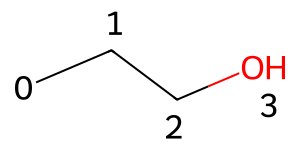

In [26]:
mol = Chem.MolFromSmiles("CCCO")

MORGAN_RADIUS = 2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, verbose=1)
display(df_morgan_iden)
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### 冗長な原子環境を除外した BitInfoMap の作成
- `MyGetBitInfoMap()` は、`MyGetMorganIdentifier()` が生成した DataFrame を受け取り、`BitInfoMap` を返す関数です。
- `includeRedundantEnvironments=True` を指定した場合は、冗長な原子環境も出力します。
#### MyGetBitInfoMap() の処理手順
- `MorganAtomEnv`
    - 採用された原子環境の情報を格納します。
    - 各要素は `(Morgan 識別子, 中心原子 index, radius)` の形式です。
- `neighborhoods`
    - これまでに採用された原子近傍領域を保持します。
    - 原子近傍領域の集合（set）として管理します。
- `radius=0` では、すべての原子環境を採用します。
    - `radius=0` の原子環境は結合を含まないため、原子近傍領域による重複判定の対象になりません。
    - そのため、すべての `(Morgan 識別子, 中心原子 index, radius=0)` を `MorganAtomEnv` に追加します。
- `radius>0` では、各 radius に対して以下の処理を行います。
    - `allNeighborhoodsThisRound` に `(原子近傍領域, Morgan 識別子, 中心原子 index)` のリストを作成します。
    - `allNeighborhoodsThisRound` をソートします。
    - 先頭から順番に処理します。
        - 原子近傍領域が `neighborhoods` に存在する場合は採用しません。
        - 存在しない場合は採用します。
            - `(Morgan 識別子, 中心原子 index, radius)` を `MorganAtomEnv` に追加します。
            - 原子近傍領域を `neighborhoods` に追加します。
- この処理を指定された最大 radius まで繰り返します。
- 最後に `MorganAtomEnv` を辞書へ変換して返します。
    - key は MorganIdentifier で、キーの順序は MorganIdentifier の昇順です。
    - value は `(中心原子 index, radius)` のタプルのリストです。

In [27]:
def MyGetBitInfoMap(df_morgan_iden, includeRedundantEnvironments=False, verbose=0):
    # includeRedundantEnvironments=False で冗長な原子環境を削除した BitInfoMap を作成する
    MorganAtomEnv = [] # 採用した Morgan Identifier (identifier、atomIdx、radius) の リスト
    neighborhoods = set() # 採用した原子近傍領域の set
    
    radius = int(df_morgan_iden.shape[1]/2) # 渡された df_morgan_iden の radius
    
    for curr_radius in range(radius):
        if curr_radius == 0: # radius=0 はすべて採用される
            if verbose:
                print(f"radius={curr_radius}")
            for atomIdx, iden in enumerate(df_morgan_iden[curr_radius]):
                MorganAtomEnv.append( (iden, atomIdx, curr_radius) )
                if verbose:
                    print(f"atom={atomIdx} MorganIdentifier={iden} atomNeighborhood=0 is retained")
            if verbose:
                print(f"MorganAtomEnv={MorganAtomEnv}")
        else: # 冗長な原子環境の削除が必要
            if verbose:
                print(f"radius={curr_radius}")
            allNeighborhoodsThisRound = [] # このradiusで作成した (原子近傍領域, Mrgan 識別子, 中心原子 index) を保存 
            for atomIdx, (iden, env) in enumerate(zip(df_morgan_iden[curr_radius], df_morgan_iden[str(curr_radius)+"_env"])):
                allNeighborhoodsThisRound.append( (env, iden, atomIdx) )
            allNeighborhoodsThisRound.sort() # sort した順番に処理が行われる 
            if verbose:
                print(f"allNeighborhoodsThisRound={allNeighborhoodsThisRound}")
            for env, iden, atomIdx in allNeighborhoodsThisRound:
                if not includeRedundantEnvironments and (env in neighborhoods): # 冗長な原子環境を除く and すでに出現した原子近傍領域
                    if verbose:
                        print(f"atomNeighborhood={env} MorganIdentifier={iden} atom={atomIdx} is removed (redundant)")
                    continue # 冗長な原子環境なので採用されない
                MorganAtomEnv.append( (iden, atomIdx, curr_radius) ) # Morgan 識別子を採用、追加する
                neighborhoods.add(env) # すでに出現した原子近傍領域に追加
                if verbose:
                    print(f"atomNeighborhood={env} MorganIdentifier={iden} atom={atomIdx} is retained",
                         f"  neighborhoods={neighborhoods}")
            if verbose:
                print(f"MorganAtomEnv={MorganAtomEnv}")

    BitInfoMap_0 = defaultdict(list) # dict 型に変換した情報を格納
    for iden, atomIdx, curr_radius in MorganAtomEnv:
        BitInfoMap_0[iden].append( (atomIdx, curr_radius) )
    BitInfoMap = {k: tuple(BitInfoMap_0[k]) for k in sorted(BitInfoMap_0)} # key の値でソートし、要素を tuple にした dict に変換
    if verbose:
        print("MorganAtomEnv convert to BitInfoMap")
        print(f"BitInfoMap={BitInfoMap}")
    return BitInfoMap

#### プロパノールでの冗長な原子環境の除外
- 各原子環境の原子近傍領域を比較して、冗長かどうかを判定します。
- `radius=0` では、すべての Morgan 識別子が採用されます。
- `radius=1` では、すべての原子近傍領域が新規に出現するため、すべての Morgan 識別子が採用されます。
- `radius=2` の原子近傍領域について確認します。
    - 原子 0 の 原子近傍領域 `3` は、`radius=1` における原子 1 の原子近傍領域と同一です。
        - そのため除外されます。
    - 原子 3 の 原子近傍領域 `6` は、`radius=1` における原子 2 の原子近傍領域と同一です。
        - そのため除外されます。
    - 原子 1 と原子 2 の 原子近傍領域はどちらも `7` です。
        - 両者は同一の原子環境として扱われます。
        - `allNeighborhoodsThisRound` は `(原子近傍領域, Morgan 識別子, 中心原子 index)` の辞書順で処理されます。
        - `(7, 1365892349, 2)` が先に処理されるため採用されます。
        - `(7, 2648393034, 1)` は冗長な原子環境として除外されます。
- 得られた結果は RDKit の出力と一致します。

Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier


,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,1747430757,3
1,2245384272,0,1173125914,3,2648393034,7
2,2245384272,0,4023654873,6,1365892349,7
3,864662311,0,1535166686,4,3729693694,6


radius=0
atom=0 MorganIdentifier=2246728737 atomNeighborhood=0 is retained
atom=1 MorganIdentifier=2245384272 atomNeighborhood=0 is retained
atom=2 MorganIdentifier=2245384272 atomNeighborhood=0 is retained
atom=3 MorganIdentifier=864662311 atomNeighborhood=0 is retained
MorganAtomEnv=[(2246728737, 0, 0), (2245384272, 1, 0), (2245384272, 2, 0), (864662311, 3, 0)]
radius=1
allNeighborhoodsThisRound=[(1, 3542456614, 0), (3, 1173125914, 1), (4, 1535166686, 3), (6, 4023654873, 2)]
atomNeighborhood=1 MorganIdentifier=3542456614 atom=0 is retained   neighborhoods={1}
atomNeighborhood=3 MorganIdentifier=1173125914 atom=1 is retained   neighborhoods={1, 3}
atomNeighborhood=4 MorganIdentifier=1535166686 atom=3 is retained   neighborhoods={1, 3, 4}
atomNeighborhood=6 MorganIdentifier=4023654873 atom=2 is retained   neighborhoods={1, 3, 4, 6}
MorganAtomEnv=[(2246728737, 0, 0), (2245384272, 1, 0), (2245384272, 2, 0), (864662311, 3, 0), (3542456614, 0, 1), (1173125914, 1, 1), (1535166686, 3, 1), (4

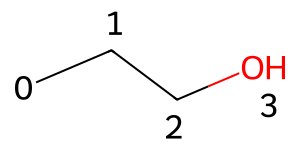

In [28]:
mol = Chem.MolFromSmiles("CCCO")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
print("Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier")
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden, verbose=1)
print("Comparison between RDKit and this Python implementation")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### シクロペンタンでの冗長な原子環境の除外
- すべての radius において、全原子が同じ Morgan 識別子を持ちます。
- `allNeighborhoodsThisRound` はソート後の順序で処理されます。
- `radius=1` では原子近傍領域の順序が `(3, 6, 12, 17, 24)` となるため、
    - `((1, 1), (2, 1), (3, 1), (0, 1), (4, 1))`
    の順序で採用されます。
- `radius=2` では原子近傍領域の順序が `(15, 23, 27, 29, 30)` となるため、
    - `((2, 2), (1, 2), (0, 2), (4, 2), (3, 2))`
    の順序で採用されます。
- 得られた結果は RDKit の出力と一致します。

Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier


,0,0_env,1,1_env,2,2_env
0,2968968094,0,2142032900,17,171200514,27
1,2968968094,0,2142032900,3,171200514,23
2,2968968094,0,2142032900,6,171200514,15
3,2968968094,0,2142032900,12,171200514,30
4,2968968094,0,2142032900,24,171200514,29


radius=0
atom=0 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=1 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=2 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=3 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=4 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
MorganAtomEnv=[(2968968094, 0, 0), (2968968094, 1, 0), (2968968094, 2, 0), (2968968094, 3, 0), (2968968094, 4, 0)]
radius=1
allNeighborhoodsThisRound=[(3, 2142032900, 1), (6, 2142032900, 2), (12, 2142032900, 3), (17, 2142032900, 0), (24, 2142032900, 4)]
atomNeighborhood=3 MorganIdentifier=2142032900 atom=1 is retained   neighborhoods={3}
atomNeighborhood=6 MorganIdentifier=2142032900 atom=2 is retained   neighborhoods={3, 6}
atomNeighborhood=12 MorganIdentifier=2142032900 atom=3 is retained   neighborhoods={3, 12, 6}
atomNeighborhood=17 MorganIdentifier=2142032900 atom=0 is retained   neighborhoods={17, 3, 12, 6}
atomNeighborhood=24 MorganIdentifier=214

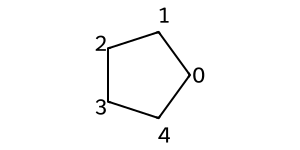

In [29]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
print("Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier")
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden, verbose=1)
print("Comparison between RDKit and this Python implementation")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### 冗長な原子環境も出力する場合
- シクロブタンを例として確認します。
- RDKit では以下のように `includeRedundantEnvironments=True` を指定します。
    - `rdFingerprintGenerator.GetMorganGenerator( radius=MORGAN_RADIUS, includeRedundantEnvironments=True )`
- 本ノートブックの実装でも同様に `includeRedundantEnvironments=True` を指定します。
    - `MyGetBitInfoMap( df_morgan_iden, includeRedundantEnvironments=True )`
- RDKit の結果と一致することが確認できます。
    - `includeRedundantEnvironments=False`（デフォルト）では除外される `radius=2` の冗長な原子環境も出力されます。

Default: includeRedundantEnvironments=False
radius=0
atom=0 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=1 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=2 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
atom=3 MorganIdentifier=2968968094 atomNeighborhood=0 is retained
MorganAtomEnv=[(2968968094, 0, 0), (2968968094, 1, 0), (2968968094, 2, 0), (2968968094, 3, 0)]
radius=1
allNeighborhoodsThisRound=[(3, 2142032900, 1), (6, 2142032900, 2), (9, 2142032900, 0), (12, 2142032900, 3)]
atomNeighborhood=3 MorganIdentifier=2142032900 atom=1 is retained   neighborhoods={3}
atomNeighborhood=6 MorganIdentifier=2142032900 atom=2 is retained   neighborhoods={3, 6}
atomNeighborhood=9 MorganIdentifier=2142032900 atom=0 is retained   neighborhoods={9, 3, 6}
atomNeighborhood=12 MorganIdentifier=2142032900 atom=3 is retained   neighborhoods={9, 3, 12, 6}
MorganAtomEnv=[(2968968094, 0, 0), (2968968094, 1, 0), (2968968094, 2, 0), (2968968094, 3, 0), (2142032900,

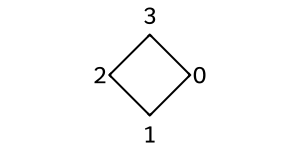

In [30]:
mol = Chem.MolFromSmiles("C1CCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)

print("Default: includeRedundantEnvironments=False")
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden, verbose=1)
print("Comparison between RDKit and this Python implementation")
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")

print("\nincludeRedundantEnvironments=True")
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden, includeRedundantEnvironments=True, verbose=1)
print("Comparison between RDKit and this Python implementation")
fpgen_redun = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeRedundantEnvironments=True)
fp = fpgen_redun.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")

d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

## 4. Morgan Fingerprint の固定長への変換
- これまでに求めた Morgan Fingerprint は、Morgan 識別子をそのまま利用するため、取り得る特徴量空間が非常に大きくなります。
- そのまま機械学習や類似度計算へ利用する場合、いくつかの課題があります。
    - Morgan 識別子は符号なし 32 ビット整数で表現されます。
        - そのため理論上は `2**32` 通りの値を取り得ます。
    - 実際の分子では、ごく一部の Morgan 識別子しか出現しません。
        - その結果、ほとんどの要素が `0` となる非常に疎なデータになります。
        - RDKit の `GetSparseCountFingerprint()` は出現回数を保持する疎な Fingerprint を返します。
        - RDKit の `GetSparseFingerprint()` は存在有無を保持する疎な Fingerprint を返します。
- このため、実際の解析では固定長へ変換した Morgan Fingerprint が広く利用されています。
- 固定長化は Morgan 識別子を `fpSize` で割った余りを利用して行います。
```text
FixedLengthIdentifier = MorganIdentifier % fpSize
```
- これにより Morgan 識別子を `0 ～ (fpSize-1)` の範囲へ写像します。
- 得られた固定長識別子について、対応する原子環境の有無や出現回数を記録します。

### シクロペンタンでの RDKit の例

- シクロペンタンには、以下の Morgan 識別子に対応する原子環境が存在します。

```text
171200514
2142032900
2968968094
```

- `2048` ビット長の Fingerprint を作成する場合、それぞれの Morgan 識別子を `2048` で割った余りを計算します。

```text
171200514  % 2048 = 2
2142032900 % 2048 = 1028
2968968094 % 2048 = 926
```

- したがって、これらの原子環境は固定長 Fingerprint のビット位置 `2`、`1028`、および `926` に対応します。
- ビットベクトル形式の Fingerprint では、
    - 原子環境が存在する場合は対応するビットを `1` に設定します。
    - 原子環境が存在しない場合は `0` のままとなります。
- 実際に RDKit を用いて `2048` ビット長の Morgan Fingerprint を生成してみます。
    - ビット位置 `2`、`926`、および `1028` が `1` に設定されます。
    - その他のビットは `0` のままです。

In [31]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
FPSIZE=2048
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for key in BitInfoMap.keys():
    print(f"MorganIdentifier= {key} % {FPSIZE} = {key % FPSIZE} (Identifier at fpsize={FPSIZE})")
fpgen_2048 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=FPSIZE)
fp_2048 = fpgen_2048.GetFingerprint(mol)
print(f"RDKit {FPSIZE} bits Morgan Fingerprint")
print(fp_2048.ToBitString())

MorganIdentifier= 171200514 % 2048 = 2 (Identifier at fpsize=2048)
MorganIdentifier= 2142032900 % 2048 = 1028 (Identifier at fpsize=2048)
MorganIdentifier= 2968968094 % 2048 = 926 (Identifier at fpsize=2048)
RDKit 2048 bits Morgan Fingerprint
0010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

### BitInfoMap から固定長ビットベクトルへの変換
- `MyGetFingerprint()` は `BitInfoMap` から、RDKit の `GetFingerprint()` が返す `ExplicitBitVect` を生成する関数です。
- `fpSize` に Fingerprint のビット長を指定します。
- `BitInfoMap` に含まれる各 Morgan 識別子について、`Morgan 識別子 % fpSize` で求めたビット位置を `1` に設定します。
- こうして固定長の Morgan Fingerprint を生成します。

In [32]:
def MyGetFingerprint(BitInfoMap, fpSize):
    # BitInfoMap から 固定長(fpSize)の Fingerprint (ExplicitBitVect) を作成する
    bv = ExplicitBitVect(fpSize)
    for key in BitInfoMap:
        bv.SetBit(key % fpSize) # Morgan 識別子 を fpSize で割った余りの位置のビットを 1 に
    return bv

- シクロペンタンについて、作成した `MyBitInfoMap` から 2048 ビット長の Fingerprint を生成してみます。
- 出力は分かりにくいですが、RDKit が生成した Fingerprint と完全に一致しています。
- 実際に `fp_2048 == Myfp_2048` は `True` になります。

In [33]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
Myfp_2048 = MyGetFingerprint(MyBitInfoMap, 2048)
print(Myfp_2048.ToBitString())
print(f"fp_2048 == Myfp_2048 -> {fp_2048 == Myfp_2048}")

0010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000

### ビット衝突（Bit Collision）
- 固定長の Fingerprint へ変換すると、異なる Morgan 識別子が同じビット位置に割り当てられる場合があります。
- この現象をビット衝突（Bit Collision）と呼びます。
    - ハッシュ衝突（Hash Collision）と呼ばれることもあります。
- ビット衝突とは、異なる原子環境から得られた異なる Morgan 識別子が、固定長化によって同じビット位置に割り当てられてしまう現象です。
#### ビット衝突の実例
- 実際の例として、ZINC15 から取得した以下の 3 化合物を用いて確認します。
    - https://zinc15.docking.org/majorclasses/ion_channel/substances/subsets/fda/
- この例では立体情報は使用していません。
- 以下の 3 化合物は、それぞれ異なる原子環境を持っています。
    - ZINC000004474460 `C=C1CC[C@H](O)C/C1=C/C=C1/CCC[C@]2(C)[C@@H]([C@H](C)CCCC(C)C)CC[C@@H]12`
    - ZINC000000897085 `O[C@@H](c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)[C@H]1CCCCN1`
    - ZINC000000075126 `Cc1nccn1C[C@@H]1CCc2c(c3ccccc3n2C)C1=O`
- しかし 2048 ビット長へ変換すると、いずれの化合物にもビット位置 `1808` に割り当てられる原子環境が存在します。
- 実際に確認すると、それぞれ異なる Morgan 識別子がビット位置 `1808` に割り当てられていることが分かります。
- その結果、3 つの化合物すべてで Fingerprint の `1808` ビット目は `1` になっています。

ZINC000000075126
MorganIdentifier= 3109601040 ((5, 2),)  (3109601040 % 2048 = 1808)
fp_2048.GetBit(1808)= True


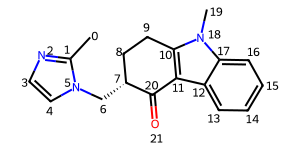

ZINC000000897085
MorganIdentifier= 298374928 ((20, 1),)  (298374928 % 2048 = 1808)
fp_2048.GetBit(1808)= True


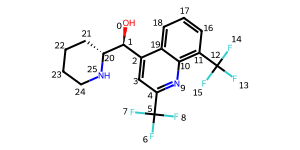

ZINC000004474460
MorganIdentifier= 1167517456 ((17, 2),)  (1167517456 % 2048 = 1808)
fp_2048.GetBit(1808)= True


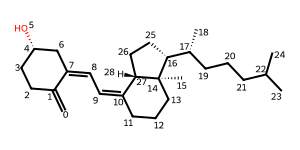

In [34]:
MORGAN_RADIUS=2
FPSIZE=2048
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
zinc_datas = [ ("ZINC000000075126", "Cc1nccn1C[C@@H]1CCc2c(c3ccccc3n2C)C1=O"),
              ("ZINC000000897085", "O[C@@H](c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)[C@H]1CCCCN1"),
              ("ZINC000004474460", "C=C1CC[C@H](O)C/C1=C/C=C1/CCC[C@]2(C)[C@@H]([C@H](C)CCCC(C)C)CC[C@@H]12") ]
for (zinc_id, zinc_smiles) in zinc_datas:
    print(zinc_id)
    mol = Chem.MolFromSmiles(zinc_smiles)
    fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
    BitInfoMap = ao.GetBitInfoMap()
    for key in BitInfoMap.keys():
        if key % FPSIZE == 1808:
            print(f"MorganIdentifier= {key} {BitInfoMap[key]}  ({key} % {FPSIZE} = {key % FPSIZE})")
    fpgen_2048 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=FPSIZE)
    fp_2048 = fpgen_2048.GetFingerprint(mol)
    print(f"fp_2048.GetBit(1808)= {fp_2048.GetBit(1808)}")
    d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
    d2d.drawOptions().addAtomIndices = True
    d2d.drawOptions().annotationFontScale =1.0
    d2d.DrawMolecule(mol)
    d2d.FinishDrawing()
    display(SVG(d2d.GetDrawingText()))

- このように、固定長化によってビット衝突が発生します。
- ビット衝突が発生すると、
    - 異なる原子環境が同じビットへ統合されます。
    - 固定長 Fingerprint から元の原子環境を完全に復元することはできません。
    - 分子間類似度の計算結果にわずかな影響を与える可能性があります。
- 一方で、Morgan Fingerprint を固定長化することで扱いやすい特徴量になるため、実用上は広く利用されています。
- 固定長 Morgan Fingerprint を用いた解析を行う際には、ビット衝突が存在することを理解した上で結果を解釈することが重要です。

## 5. 立体情報および同位体情報の例
- 最後に、幾何異性体、鏡像異性体、および同位体を含む分子について Morgan Fingerprint の計算例を示します。
- これらの例を通して、立体情報や同位体情報が Morgan 識別子にどのように反映されるかを確認します。
    - 本ノートブックでは、立体情報（Stereochemical Information）として、原子の立体情報（Chirality Information）と結合の立体情報（Double-Bond Stereochemistry Information）を扱います。
- あわせて、Python 実装によって計算した Morgan 識別子が RDKit の結果と一致することを確認します。

### 立体情報を考慮する場合
- RDKit で立体情報を含む Morgan Fingerprint を生成するには、以下のように `includeChirality=True` を指定します。
    - `rdFingerprintGenerator.GetMorganGenerator(radius=2, includeChirality=True)`
    - これにより、原子の立体情報と結合の立体情報の両方が Morgan Fingerprint の計算に反映されます。
- 本ノートブックの実装でも同様に `includeChirality=True` を指定します。
    - `MyGetMorganIdentifier(mol, radius=2, includeChirality=True, verbose=1)`
    - この場合も、原子の立体情報と結合の立体情報の両方が Morgan Fingerprint の計算に反映されます。
- `includeChirality=False` (デフォルト) の場合、立体情報 (Stereochemical Information) は Morgan 識別子の計算に利用されません。

### 幾何異性体での Morgan 識別子の計算
- trans-2-pentene (`C\C=C\CC`) と cis-2-pentene (`C\C=C/CC`) を例として確認します。
- まず、結合の立体情報を使用した場合の結果を示します。
    - `C\C=C\CC` の例
    - `C\C=C/CC` の例
- 両者を比較すると、二重結合に対応する Bond Invariant が異なっていることが分かります。
- E/Z 情報は Bond Invariant に反映されるため、`radius=1` および `radius=2` における Morgan 識別子も異なります。
- 一方で、結合の立体情報の影響を受けない原子環境については同じ Morgan 識別子が得られます。
- いずれの場合も、Python 実装と RDKit の結果は一致しています。

Example of C\C=C\CC
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736708276 Neighbor=[(1, 2246728737), (125, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530222952 Neighbor=[(1, 2245384272), (125, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402080175 Neighbo

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402080175,3
1,2246703798,0,736708276,3,2102851056,7
2,2246703798,0,530222952,6,1741163965,15
3,2245384272,0,2065620398,12,3406717757,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530222952 ((2, 1),)  my_identifier 530222952 ((2, 1),) True
MorganIdentifier=736708276 ((1, 1),)  my_identifier 736708276 ((1, 1),) True
MorganIdentifier=1741163965 ((2, 2),)  my_identifier 1741163965 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2102851056 ((1, 2),)  my_identifier 2102851056 ((1, 2),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406717757 ((3, 2),)  my_identifier 3406717757 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


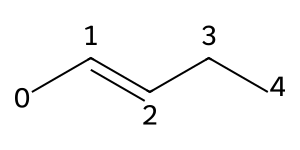

In [35]:
mol = Chem.MolFromSmiles("C\C=C\CC")
print("Example of C\C=C\CC")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

Example of C\C=C/CC
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736708341 Neighbor=[(1, 2246728737), (124, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530222891 Neighbor=[(1, 2245384272), (124, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402080116 Neighbo

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402080116,3
1,2246703798,0,736708341,3,2100976915,7
2,2246703798,0,530222891,6,1741682072,15
3,2245384272,0,2065620398,12,3406476695,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530222891 ((2, 1),)  my_identifier 530222891 ((2, 1),) True
MorganIdentifier=736708341 ((1, 1),)  my_identifier 736708341 ((1, 1),) True
MorganIdentifier=1741682072 ((2, 2),)  my_identifier 1741682072 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2100976915 ((1, 2),)  my_identifier 2100976915 ((1, 2),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406476695 ((3, 2),)  my_identifier 3406476695 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


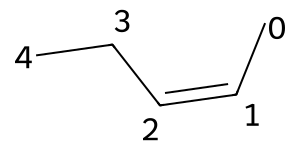

In [36]:
mol = Chem.MolFromSmiles("C\C=C/CC")
print("Example of C\\C=C/CC")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### 立体情報を使用しない場合
- 次に、`includeChirality=False` の場合を確認します。
    - `C\C=C/CC with includeChirality=False`
- この場合、E/Z 情報は使用されません。
- 二重結合は単に「二重結合」として扱われます。
- そのため、cis 体と trans 体は同じ Morgan 識別子を生成します。
- 立体情報を考慮した場合とは異なる Morgan 識別子になりますが、RDKit の結果とは一致しています。

C\C=C/CC with includeChirality=False
MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736731344 Neighbor=[(1, 2246728737), (2, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530246988 Neighbor=[(1, 2245384272), (2, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402058131,3
1,2246703798,0,736731344,3,1738749468,7
2,2246703798,0,530246988,6,1761408361,15
3,2245384272,0,2065620398,12,3406031982,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530246988 ((2, 1),)  my_identifier 530246988 ((2, 1),) True
MorganIdentifier=736731344 ((1, 1),)  my_identifier 736731344 ((1, 1),) True
MorganIdentifier=1738749468 ((1, 2),)  my_identifier 1738749468 ((1, 2),) True
MorganIdentifier=1761408361 ((2, 2),)  my_identifier 1761408361 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406031982 ((3, 2),)  my_identifier 3406031982 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


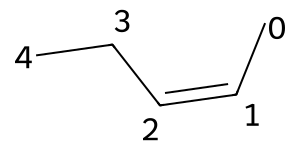

In [37]:
mol = Chem.MolFromSmiles("C\C=C/CC")
print("C\\C=C/CC with includeChirality=False")
includeChirality=False
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### 鏡像異性体での Morgan 識別子の計算
- 次に、鏡像異性体である `CC[C@@](F)(Cl)Br` と `CC[C@](F)(Cl)Br` を例として確認します。
- まず、原子の立体情報を使用した場合の結果を示します。
    - `CC[C@@](F)(Cl)Br` の例
    - `CC[C@](F)(Cl)Br` の例
- 不斉中心となる原子では `LooksChiral` の値が異なります。
    - R 配置では `3`
    - S 配置では `2`
- この違いが Morgan 識別子の計算に反映されます。
- その結果、`radius=1` および `radius=2` における Morgan 識別子が異なります。
- いずれの場合も、Python 実装と RDKit の結果は一致しています。

Example of CC[C@@](F)(Cl)Br
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=3821193030 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=3 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2245277810)] Looks

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,4067363791,31
2,2245277810,0,3821193030,30,2111933619,31
3,882399112,0,485463469,4,4214232094,30
4,1016841875,0,170894115,8,588079498,30
5,3612926680,0,325281617,16,1798477929,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2111933619 ((2, 2),)  my_identifier 2111933619 ((2, 2),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
MorganIdentifier=3612926680 ((5, 0),)  my_identifier 3612926680 ((5, 0),) True
Morg

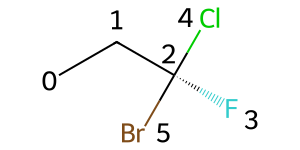

In [38]:
mol = Chem.MolFromSmiles("CC[C@@](F)(Cl)Br")
print("Example of CC[C@@](F)(Cl)Br")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

Example of CC[C@](F)(Cl)Br
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=3821193029 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=2 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2245277810)] LooksC

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,4067363788,31
2,2245277810,0,3821193029,30,3499573409,31
3,882399112,0,485463469,4,4214232095,30
4,1016841875,0,170894115,8,588079499,30
5,3612926680,0,325281617,16,1798477930,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3499573409 ((2, 2),)  my_identifier 3499573409 ((2, 2),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
MorganIdentifier=3612926680 ((5, 0),)  my_identifier 3612926680 ((5, 0),) True
Morg

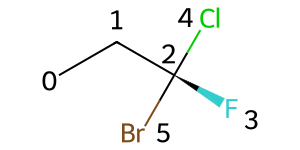

In [39]:
mol = Chem.MolFromSmiles("CC[C@](F)(Cl)Br")
print("Example of CC[C@](F)(Cl)Br")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### 立体情報を使用しない場合
- 次に、`includeChirality=False` の場合を確認します。
    - `CC[C@](F)(Cl)Br with includeChirality=False`
- `includeChirality=False` の場合、不斉中心の立体情報は利用されません。
- そのため、互いに鏡像関係にある分子であっても同じ Morgan 識別子が生成されます。
- また、立体情報を含めた場合と比較すると、冗長な原子環境の除外結果が変化する場合があります。
- この例では `radius=2` の原子環境の採用順序が変化し、`BitInfoMap` に含まれる原子環境も異なっています。
- ただし、RDKit と同じ結果が得られていることが確認できます。

CC[C@](F)(Cl)Br with includeChirality=False
MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=1408502088 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=0 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,2041435466,31
2,2245277810,0,1408502088,30,4047137456,31
3,882399112,0,485463469,4,1799541264,30
4,1016841875,0,170894115,8,3017679752,30
5,3612926680,0,325281617,16,3681409643,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1408502088 ((2, 1),)  my_identifier 1408502088 ((2, 1),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2041435466 ((1, 2),)  my_identifier 2041435466 ((1, 2),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
Morg

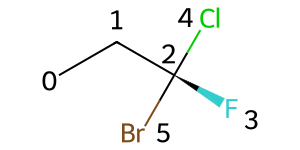

In [40]:
mol = Chem.MolFromSmiles("CC[C@](F)(Cl)Br")
print("CC[C@](F)(Cl)Br with includeChirality=False")
includeChirality=False # 立体情報を使用しない
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### 同位体情報を含む場合
- 最後に、同位体を含む分子 `CC([13CH3])[14CH3]` を例として確認します。
- 同位体情報は原子コンポーネントの「標準原子量との差分」として扱われます。
- 本ノートブックでは以下の値を使用しています。
    - `delta_mass = int(actual_mass - standard_mass)`
- ここで `int()` による整数化が行われるため、小数部分は切り捨てられます。
- その結果、
    - 原子 2 の `[13C]` は通常の `[12C]` と同じ `delta_mass=0`
    - 原子 3 の `[14C]` は `delta_mass=1`
- となります。
- このため、原子 2 の `[13C]` と 原子 0 の `[12C]` は同じ Morgan 識別子になります。
- 一方で、原子 3 の `[14C]` は異なる Morgan 識別子になります。
- Python 実装と RDKit の結果は一致しています。

Example of CC([13CH3])[14CH3]
delta_mass
atom= 0 Mass= 12.011  delta_mass= int(12.011 - 12.011) = int(0.0) = 0
atom= 1 Mass= 12.011  delta_mass= int(12.011 - 12.011) = int(0.0) = 0
atom= 2 Mass= 13.00335484  delta_mass= int(13.00335484 - 12.011) = int(0.9923548400000008) = 0
atom= 3 Mass= 14.00324199  delta_mass= int(14.00324199 - 12.011) = int(1.9922419900000001) = 1
MyGetMorganIdentifier: radius=1 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245273601 components=[6, 4, 1, 0, 0]
atom=2 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=3 MorganIdentifier=2246728742 components=[6, 4, 3, 0, 1]
radius=1
atom=0 MorganIdentifier=3537119515 Neighbor=[(1, 2245273601)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1511968924 Neighbor=[(1, 2246728737), (1, 2246728737), (1, 2246728742)] LooksChiral=0 atomNeighborhood=0b111
atom=2 MorganIdentifier=3537119515 Neighbor=[(1, 2245273601)] LooksChiral=0 at

,0,0_env,1,1_env
0,2246728737,0,3537119515,1
1,2245273601,0,1511968924,7
2,2246728737,0,3537119515,2
3,2246728742,0,3537120221,4


Comparison between RDKit and this Python implementation
MorganIdentifier=1511968924 ((1, 1),)  my_identifier 1511968924 ((1, 1),) True
MorganIdentifier=2245273601 ((1, 0),)  my_identifier 2245273601 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0), (2, 0))  my_identifier 2246728737 ((0, 0), (2, 0)) True
MorganIdentifier=2246728742 ((3, 0),)  my_identifier 2246728742 ((3, 0),) True
MorganIdentifier=3537119515 ((0, 1), (2, 1))  my_identifier 3537119515 ((0, 1), (2, 1)) True
MorganIdentifier=3537120221 ((3, 1),)  my_identifier 3537120221 ((3, 1),) True


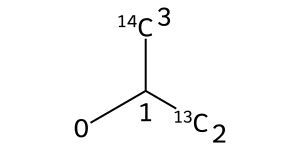

In [41]:
mol = Chem.MolFromSmiles("CC([13CH3])[14CH3]")
print("Example of CC([13CH3])[14CH3]")
ptable = Chem.GetPeriodicTable()
print("delta_mass")
for atom in mol.GetAtoms():
    mass = atom.GetMass()
    std_mass = ptable.GetAtomicWeight(atom.GetAtomicNum())
    print(f"atom= {atom.GetIdx()} Mass= {mass}  delta_mass= int({mass} - {std_mass}) = int({mass-std_mass}) = {int(mass-std_mass)}")

curr_radius = 1
df_morgan_iden = MyGetMorganIdentifier(mol, radius=curr_radius, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen2 = rdFingerprintGenerator.GetMorganGenerator(radius=curr_radius)
fp = fpgen2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### 最後に
- Morgan Fingerprint の仕組みを理解したくて、RDKit のソースコードを参考にしながら Python で実装してみました。
- 実際に手を動かしてみることで、Atom Invariant の生成から Morgan 識別子の計算、冗長な原子環境の除外、固定長 Fingerprint への変換までの流れを以前より具体的に理解できたように思います。
- 特に、普段はあまり意識することのない中間計算結果を追いかけてみることで、Morgan Fingerprint がどのように構築されているのかを確認できました。
- 実装はあくまでも学習目的の試作ですが、同じようにアルゴリズムの内部処理に興味のある方の参考になれば嬉しく思います。